# Etapa 3: Construção e avaliação dos classificadores

**Trabalho em Competição: Detecção de Intrusão em Redes** · Inteligência Artificial · Profa. Cristiane Neri Nobre

Nesta etapa treinamos e comparamos os três algoritmos do grupo (**árvore de decisão**, **random forest** e **rede neural MLP treinada por backpropagation**), cruzando cada um com as técnicas de pré-processamento, e escolhemos o melhor modelo **só pela validação cruzada no treino**. O teste não é usado aqui.

**De onde partimos:** o pipeline escolhido na Etapa 2. A limpeza é o `limpar()` de `limpeza.py`, seguido de mediana nos números, moda nos textos, `log1p` nas contagens, `StandardScaler` e one-hot com os serviços raros juntos. A Etapa 2 não usou balanceamento nem PCA.

**Uso de IA:** usamos o Claude (Anthropic) para apoio na escrita do código dos experimentos (`experimentos.py`, células marcadas com `[IA]`) e na revisão do texto. As decisões e a conferência dos resultados foram do grupo.

## 1. Como avaliamos

- **Os mesmos folds de todo o grupo:** `RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)` no `treino_limpo.csv`, o que dá 10 medidas por experimento. Como todos os experimentos usam os mesmos folds, dá para comparar fold a fold.
- **Tudo dentro do fold:** imputação, escala, codificação, balanceamento e até os modelos de imputação são ajustados só no treino de cada fold. A validação só é transformada.
- **Limiar de decisão:** o F1-macro depende do ponto de corte da probabilidade. Para cada fold, escolhemos o limiar (de 0,02 a 0,98) que maximiza o F1-macro **nos outros 4 folds da mesma repetição** e só então medimos o fold. Assim o limiar nunca é escolhido olhando o fold avaliado. Mostramos também o F1 com o limiar padrão de 0,5.
- **Regra para aceitar uma técnica:** ganho médio positivo **e** vitória em ≥ 8 dos 10 folds (a regra da Etapa 2) **ou** p < 0,10 no teste t corrigido para validação cruzada repetida (Bouckaert & Frank, 2004). O teste t comum dá "diferença significativa" demais, porque os folds compartilham linhas de treino.
- **Reaproveitamento:** todos os experimentos ficam registrados em `resultados_experimentos/resultados_experimentos.jsonl`. Com `ex.RODAR_TUDO = False`, o notebook reaproveita o resultado salvo de cada configuração. Com `True`, refaz tudo do zero, o que leva de 2 a 3 h em 2 núcleos.

In [1]:
# [IA] Pastas do projeto: este notebook fica na pasta da sua etapa, e os dados
# (BANCO_DE_DADOS/) e o código (codigo/) ficam na pasta principal do projeto.
import os, sys
from pathlib import Path
PASTA_NOTEBOOK = Path.cwd()
if not Path("BANCO_DE_DADOS").is_dir():
    os.chdir(PASTA_NOTEBOOK.parent)
sys.path.insert(0, str(Path("codigo").resolve()))
print("pasta do projeto:", Path.cwd().name, "| notebook em:", PASTA_NOTEBOOK.name)

pasta do projeto: teste_pastas | notebook em: Etapa 3 - Classificadores


In [2]:
# [IA] Configuração
import json, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import experimentos as ex

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
ex.RODAR_TUDO = False
AZUL, LARANJA, VERDE, CINZA = "#2a6fdb", "#d95f02", "#1b9e77", "#8a8a8a"
print(f"treino limpo: {ex.X.shape[0]} linhas, {ex.X.shape[1]} atributos, {ex.Y.mean()*100:.2f}% de anomalias")
print(f"pares contraditórios guardados (para o teste de reetiquetagem): {len(ex.PARES)}")
print(f"folds: {len(ex.FOLDS)} | validação de cada fold: {len(ex.FOLDS[0][1])} linhas")

treino limpo: 55074 linhas, 41 atributos, 3.30% de anomalias
pares contraditórios guardados (para o teste de reetiquetagem): 1702
folds: 10 | validação de cada fold: 11015 linhas


In [3]:
# [IA] A função de avaliação usada em todos os experimentos
print(inspect.getsource(ex.avaliar))

def avaliar(rotulo, cfg=None, nome="rf", params=None, balanc="none", pares=False, folds=range(10), salvar=True):
    """F1-macro por fold com limiar 0,5 e com limiar escolhido nos OUTROS folds da mesma repetição."""
    cfg = cfg or {}
    t0 = time.time()
    folds = list(folds)
    probs = Parallel(n_jobs=N_JOBS)(delayed(rodar_fold)(f, cfg, nome, params, balanc, pares) for f in folds)
    P = {f: p for f, p in zip(folds, probs)}
    chave_p = hashlib.md5(json.dumps([cfg, nome, params, balanc, pares], sort_keys=True, default=str).encode()).hexdigest()[:16]
    pickle.dump(P, open(os.path.join(CACHE, f"probs_{chave_p}.pkl"), "wb"))
    f05, ft, lims = {}, {}, {}
    for f in folds:
        _, iva = FOLDS[f]
        f05[f] = _f1(Y[iva], P[f], 0.5)
        rep = f // 5
        outros = [g for g in folds if g // 5 == rep and g != f]
        if outros:
            yo = np.concatenate([Y[FOLDS[g][1]] for g in outros]); po = np.concatenate([P[g] for g in outros])
            t = max(GRADE, k

## 2. Referências

Antes de tudo, a referência mais simples possível: um classificador que responde sempre `normal`, a classe majoritária. Ele mostra por que a acurácia engana nesta base. Depois rodamos os três algoritmos com o pipeline da Etapa 2, sem nenhuma mudança.

In [4]:
# [IA] Classe majoritária: acurácia alta, F1-macro baixo
from sklearn.metrics import f1_score, accuracy_score
acc, f1m = [], []
for _, iva in ex.FOLDS:
    y = ex.Y[iva]; pred = np.zeros_like(y)
    acc.append(accuracy_score(y, pred)); f1m.append(f1_score(y, pred, average="macro"))
print(f"Classe majoritária → acurácia {np.mean(acc):.4f} | F1-macro {np.mean(f1m):.4f}")

Classe majoritária → acurácia 0.9670 | F1-macro 0.4916


In [5]:
# [IA] Os três algoritmos com o pipeline da Etapa 2
MODELOS = {"arvore": "Árvore de decisão", "rf": "Random forest (100 árvores)", "mlp": "MLP (64 neurônios)"}
ref_etapa2 = {m: ex.rodar(f"{nome}: pipeline da Etapa 2", {}, m) for m, nome in MODELOS.items()}
pd.DataFrame({nome: {"F1-macro (limiar 0,5)": ref_etapa2[m]["media_05"], "F1-macro (limiar ajustado)": ref_etapa2[m]["media_lim"],
                     "desvio": ref_etapa2[m]["desvio_lim"], "limiar mediano": np.median(ref_etapa2[m]["limiares"])}
              for m, nome in MODELOS.items()}).T.round(4)

Árvore de decisão: pipeline da Etapa 2                         F1 lim 0,5: 0.9664 | lim ajustado: 0.9664 ± 0.0038 (lim ~0.51) [salvo]


Random forest (100 árvores): pipeline da Etapa 2               F1 lim 0,5: 0.9756 | lim ajustado: 0.9815 ± 0.0034 (lim ~0.34) [salvo]


MLP (64 neurônios): pipeline da Etapa 2                        F1 lim 0,5: 0.9636 | lim ajustado: 0.9629 ± 0.0066 (lim ~0.45) [salvo]


,"F1-macro (limiar 0,5)",F1-macro (limiar ajustado),desvio,limiar mediano
Árvore de decisão,0.9664,0.9664,0.0038,0.510
Random forest (100 árvores),0.9756,0.9815,0.0034,0.335
MLP (64 neurônios),0.9636,0.9629,0.0066,0.445


**Conclusão do passo 2**

- A classe majoritária tem **acurácia de 0,967**, mas **F1-macro de 0,49**: ela nunca encontra uma anomalia. É o exemplo do enunciado de por que a acurácia não serve aqui.
- Com o pipeline da Etapa 2, a **random forest** já sai na frente (0,9756 com limiar 0,5). Depois vêm a árvore (0,9664) e a MLP (0,9636). A MLP sai atrás porque o pipeline da Etapa 2 foi escolhido olhando a RF e a regressão logística, não uma rede.
- **Só ajustar o limiar** já leva a random forest de 0,9756 para **0,9815**, com limiar mediano em torno de 0,34. Isso bate com Lipton et al. (2014): o limiar ótimo do F1 fica abaixo de 0,5. Na árvore o limiar não muda nada, porque as folhas de uma árvore sem poda dão probabilidade 0 ou 1.

## 3. Pré-processamento × algoritmo

Para cada algoritmo, partimos do pipeline da Etapa 2 e testamos **uma técnica por vez**, como recomendam Kuhn & Johnson (2019). Uma técnica que passa na regra entra no pipeline daquele modelo, e a próxima é testada em cima dela. As técnicas, quase todas inspiradas nos livros e artigos que o grupo consultou:

| Técnica | O que faz | Por que testar |
|---|---|---|
| `service`/`flag` por random forest | uma floresta treinada nas outras colunas adivinha a categoria ausente | a moda acerta 57% dos `service` escondidos; a floresta, 97% |
| números: mediana por `service` | mediana dentro do mesmo serviço | um `src_bytes` de http é diferente de um de ftp |
| números: MissForest | imputação iterativa com árvores (Stekhoven & Bühlmann, 2012) | usa a relação entre as colunas |
| números: pela definição | recalcula pela definição do atributo, como `serror_rate` ≈ `srv_serror_rate` (98% exato) e `same_srv_rate` = 1 − `diff_srv_rate` | recupera ausentes sem chutar |
| atributos novos | indicadores de bytes = 0, razões de bytes e contagens, taxas de erro totais | engenharia de atributos (Zheng & Casari, 2018) |
| filtro de variância quase zero | tira colunas quase constantes, sem olhar a classe | redes neurais sofrem com atributos inúteis (Grinsztajn et al., 2022) |
| corte nos percentis (só MLP) | limita os extremos que sobram depois do `log1p` | árvores não mudam com transformações monótonas |
| oversampling aleatório (árvore e MLP) | repete anomalias até as classes empatarem | foi o melhor balanceamento nos testes exploratórios; balancear ajuda modelos "fracos" (Elor & Averbuch-Elor, 2022) |
| pares contraditórios reetiquetados | devolve ao treino os 1.702 pares removidos, com o rótulo previsto pelo próprio modelo do fold | os pares têm muitos ataques reais (Northcutt et al., 2021) |

In [6]:
# [IA] Seleção passo a passo (mesma lógica para os três modelos)
def aceita(novo, ref):
    g, v, k, p = ex.comparar(novo, ref)
    return g, v, p, (g > 0 and (v >= 8 or p < 0.10))

def passo_a_passo(m, params=None):
    cfg, balanc, pares, linhas = {}, "none", False, []
    tag = f"[{m}{'×3' if params else ''}]"
    ref = ex.rodar(f"{tag} referência", {}, m, params)
    linhas.append(dict(passo="pipeline da Etapa 2", f1_05=ref["media_05"], f1=ref["media_lim"], ganho=np.nan, vence="", p=np.nan, decisao="referência"))
    def testa(rot, c, b=None, pa=None):
        nonlocal ref
        r = ex.rodar(f"{tag} + {rot}", c, m, params, b or balanc, pares if pa is None else pa)
        g, v, p, ok = aceita(r, ref)
        linhas.append(dict(passo=rot, f1_05=r["media_05"], f1=r["media_lim"], ganho=g, vence=f"{v}/10", p=p, decisao="ACEITA" if ok else "rejeitada"))
        return r, ok
    r, ok = testa("service/flag por random forest", {**cfg, "cat": "rf"})
    if ok: cfg["cat"] = "rf"; ref = r
    melhor = None
    opcoes = [("números: mediana por service", dict(num="servico")), ("números: MissForest", dict(num="missforest")),
              ("números: pela definição + mediana", dict(num="definicao"))]
    if params is not None:   # MLP com 3 sementes: só o MissForest, a única que tinha ido bem com 1 semente
        opcoes = opcoes[1:2]
    for rot, mud in opcoes:
        r, ok = testa(rot, {**cfg, **mud})
        if ok and (melhor is None or r["media_lim"] > melhor[1]["media_lim"]): melhor = (mud, r)
    if melhor: cfg.update(melhor[0]); ref = melhor[1]
    if params is None:   # na MLP com 3 sementes testamos só o que tinha chance (ver texto)
        fe = []
        for nome_fe, rot in [("zeros", "atributo: bytes == 0"), ("razoes", "atributo: razões"), ("erros", "atributo: taxas de erro totais")]:
            r, ok = testa(rot, {**cfg, "fe": tuple(fe + [nome_fe])})
            if ok: fe.append(nome_fe); cfg["fe"] = tuple(fe); ref = r
        r, ok = testa("filtro de variância quase zero", {**cfg, "nzv": True})
        if ok: cfg["nzv"] = True; ref = r
    if m == "mlp":
        melhor = None
        for clip in ([(1, 99), (0.5, 99.5)] if params is None else [(0.5, 99.5)]):
            r, ok = testa(f"corte nos percentis {clip}", {**cfg, "clip": clip})
            if ok and (melhor is None or r["media_lim"] > melhor[1]["media_lim"]): melhor = (clip, r)
        if melhor: cfg["clip"] = melhor[0]; ref = melhor[1]
    if m in ("mlp", "arvore"):
        r, ok = testa("oversampling aleatório", cfg, b="ros")
        if ok: balanc = "ros"; ref = r
    if params is None:
        r, ok = testa("pares contraditórios reetiquetados", cfg, pa=True)
        if ok: pares = True; ref = r
    return pd.DataFrame(linhas), dict(cfg={**ex.PADRAO, **cfg}, balanc=balanc, pares=pares, ref=ref)

In [7]:
# [IA] Árvore de decisão
tab_arvore, esc_arvore = passo_a_passo("arvore")
tab_arvore.round(4)

[arvore] referência                                            F1 lim 0,5: 0.9664 | lim ajustado: 0.9664 ± 0.0038 (lim ~0.51) [salvo]


[arvore] + service/flag por random forest                      F1 lim 0,5: 0.9691 | lim ajustado: 0.9691 ± 0.0047 (lim ~0.02) [salvo]


[arvore] + números: mediana por service                        F1 lim 0,5: 0.9654 | lim ajustado: 0.9654 ± 0.0039 (lim ~0.02) [salvo]


[arvore] + números: MissForest                                 F1 lim 0,5: 0.9667 | lim ajustado: 0.9667 ± 0.0048 (lim ~0.02) [salvo]


[arvore] + números: pela definição + mediana                   F1 lim 0,5: 0.9683 | lim ajustado: 0.9683 ± 0.0037 (lim ~0.51) [salvo]


[arvore] + atributo: bytes == 0                                F1 lim 0,5: 0.9661 | lim ajustado: 0.9661 ± 0.0048 (lim ~0.51) [salvo]


... (2 outputs left out)

[arvore] + filtro de variância quase zero                      F1 lim 0,5: 0.9610 | lim ajustado: 0.9613 ± 0.0047 (lim ~0.43) [salvo]


[arvore] + oversampling aleatório                              F1 lim 0,5: 0.9561 | lim ajustado: 0.9560 ± 0.0063 (lim ~0.02) [salvo]


[arvore] + pares contraditórios reetiquetados                  F1 lim 0,5: 0.9648 | lim ajustado: 0.9648 ± 0.0049 (lim ~0.67) [salvo]


,passo,f1_05,f1,ganho,vence,p,decisao
0,pipeline da Etapa 2,0.9664,0.9664,NaN,,NaN,referência
1,service/flag por random forest,0.9691,0.9691,0.0027,7/10,0.2989,rejeitada
2,números: mediana por service,0.9654,0.9654,-0.0010,3/10,0.7304,rejeitada
3,números: MissForest,0.9667,0.9667,0.0003,5/10,0.9262,rejeitada
4,números: pela definição + mediana,0.9683,0.9683,0.0019,5/10,0.4763,rejeitada
5,atributo: bytes == 0,0.9661,0.9661,-0.0003,4/10,0.8516,rejeitada
6,atributo: razões,0.9650,0.9652,-0.0012,2/10,0.4179,rejeitada
7,atributo: taxas de erro totais,0.9665,0.9665,0.0001,4/10,0.9767,rejeitada
8,filtro de variância quase zero,0.9610,0.9613,-0.0051,1/10,0.2455,rejeitada
9,oversampling aleatório,0.9561,0.9560,-0.0104,0/10,0.0069,rejeitada


In [8]:
# [IA] Random forest
tab_rf, esc_rf = passo_a_passo("rf")
tab_rf.round(4)

[rf] referência                                                F1 lim 0,5: 0.9756 | lim ajustado: 0.9815 ± 0.0034 (lim ~0.34) [salvo]


[rf] + service/flag por random forest                          F1 lim 0,5: 0.9763 | lim ajustado: 0.9834 ± 0.0027 (lim ~0.35) [salvo]


[rf] + números: mediana por service                            F1 lim 0,5: 0.9770 | lim ajustado: 0.9838 ± 0.0030 (lim ~0.35) [salvo]


[rf] + números: MissForest                                     F1 lim 0,5: 0.9744 | lim ajustado: 0.9813 ± 0.0022 (lim ~0.33) [salvo]


[rf] + números: pela definição + mediana                       F1 lim 0,5: 0.9779 | lim ajustado: 0.9820 ± 0.0033 (lim ~0.36) [salvo]


[rf] + atributo: bytes == 0                                    F1 lim 0,5: 0.9771 | lim ajustado: 0.9830 ± 0.0029 (lim ~0.35) [salvo]

[rf] + atributo: razões                                        F1 lim 0,5: 0.9770 | lim ajustado: 0.9817 ± 0.0031 (lim ~0.35) [salvo]


[rf] + atributo: taxas de erro totais                          F1 lim 0,5: 0.9758 | lim ajustado: 0.9821 ± 0.0029 (lim ~0.36) [salvo]


[rf] + filtro de variância quase zero                          F1 lim 0,5: 0.9706 | lim ajustado: 0.9740 ± 0.0047 (lim ~0.39) [salvo]


[rf] + pares contraditórios reetiquetados                      F1 lim 0,5: 0.9779 | lim ajustado: 0.9790 ± 0.0036 (lim ~0.36) [salvo]


,passo,f1_05,f1,ganho,vence,p,decisao
0,pipeline da Etapa 2,0.9756,0.9815,NaN,,NaN,referência
1,service/flag por random forest,0.9763,0.9834,0.0019,9/10,0.0711,ACEITA
2,números: mediana por service,0.9770,0.9838,0.0004,5/10,0.6715,rejeitada
3,números: MissForest,0.9744,0.9813,-0.0021,1/10,0.0991,rejeitada
4,números: pela definição + mediana,0.9779,0.9820,-0.0014,3/10,0.2281,rejeitada
5,atributo: bytes == 0,0.9771,0.9830,-0.0004,4/10,0.6795,rejeitada
6,atributo: razões,0.9770,0.9817,-0.0017,3/10,0.3625,rejeitada
7,atributo: taxas de erro totais,0.9758,0.9821,-0.0013,2/10,0.0903,rejeitada
8,filtro de variância quase zero,0.9706,0.9740,-0.0094,0/10,0.0044,rejeitada
9,pares contraditórios reetiquetados,0.9779,0.9790,-0.0044,1/10,0.0122,rejeitada


In [9]:
# [IA] MLP com uma semente
tab_mlp1, _ = passo_a_passo("mlp")
tab_mlp1.round(4)

[mlp] referência                                               F1 lim 0,5: 0.9636 | lim ajustado: 0.9629 ± 0.0066 (lim ~0.45) [salvo]


[mlp] + service/flag por random forest                         F1 lim 0,5: 0.9646 | lim ajustado: 0.9642 ± 0.0035 (lim ~0.51) [salvo]


[mlp] + números: mediana por service                           F1 lim 0,5: 0.9613 | lim ajustado: 0.9617 ± 0.0060 (lim ~0.46) [salvo]


[mlp] + números: MissForest                                    F1 lim 0,5: 0.9652 | lim ajustado: 0.9656 ± 0.0076 (lim ~0.34) [salvo]


[mlp] + números: pela definição + mediana                      F1 lim 0,5: 0.9642 | lim ajustado: 0.9636 ± 0.0050 (lim ~0.57) [salvo]


[mlp] + atributo: bytes == 0                                   F1 lim 0,5: 0.9583 | lim ajustado: 0.9588 ± 0.0080 (lim ~0.37) [salvo]


... (4 outputs left out)

[mlp] + corte nos percentis (0.5, 99.5)                        F1 lim 0,5: 0.9637 | lim ajustado: 0.9633 ± 0.0046 (lim ~0.40) [salvo]


[mlp] + oversampling aleatório                                 F1 lim 0,5: 0.9584 | lim ajustado: 0.9655 ± 0.0037 (lim ~0.92) [salvo]


[mlp] + pares contraditórios reetiquetados                     F1 lim 0,5: 0.9620 | lim ajustado: 0.9610 ± 0.0074 (lim ~0.48) [salvo]


,passo,f1_05,f1,ganho,vence,p,decisao
0,pipeline da Etapa 2,0.9636,0.9629,NaN,,NaN,referência
1,service/flag por random forest,0.9646,0.9642,0.0014,6/10,0.6891,rejeitada
2,números: mediana por service,0.9613,0.9617,-0.0012,6/10,0.8602,rejeitada
3,números: MissForest,0.9652,0.9656,0.0027,6/10,0.3768,rejeitada
4,números: pela definição + mediana,0.9642,0.9636,0.0008,4/10,0.8187,rejeitada
5,atributo: bytes == 0,0.9583,0.9588,-0.0041,1/10,0.2163,rejeitada
6,atributo: razões,0.9620,0.9623,-0.0006,5/10,0.7917,rejeitada
7,atributo: taxas de erro totais,0.9600,0.9587,-0.0041,3/10,0.3267,rejeitada
8,filtro de variância quase zero,0.9492,0.9490,-0.0139,0/10,0.0130,rejeitada
9,"corte nos percentis (1, 99)",0.9634,0.9631,0.0002,3/10,0.9215,rejeitada


**Por que a MLP aparece duas vezes:** com uma semente só, o F1 da MLP varia ± 0,0066 entre os folds, o dobro da random forest. Boa parte disso vem do sorteio dos pesos iniciais, então diferenças de 0,002–0,003 ficam escondidas no ruído e nada passa na regra. Por isso repetimos as técnicas promissoras com a **média de 3 redes** treinadas com sementes diferentes, o que deixa a comparação mais estável.

In [10]:
# [IA] MLP: média de 3 redes com sementes diferentes
tab_mlp3, esc_mlp = passo_a_passo("mlp", {"sementes": 3})
tab_mlp3.round(4)

[mlp×3] referência                                             F1 lim 0,5: 0.9637 | lim ajustado: 0.9623 ± 0.0066 (lim ~0.49) [salvo]


[mlp×3] + service/flag por random forest                       F1 lim 0,5: 0.9652 | lim ajustado: 0.9640 ± 0.0047 (lim ~0.46) [salvo]


[mlp×3] + números: MissForest                                  F1 lim 0,5: 0.9691 | lim ajustado: 0.9698 ± 0.0057 (lim ~0.40) [salvo]


[mlp×3] + corte nos percentis (0.5, 99.5)                      F1 lim 0,5: 0.9696 | lim ajustado: 0.9691 ± 0.0045 (lim ~0.40) [salvo]


[mlp×3] + oversampling aleatório                               F1 lim 0,5: 0.9694 | lim ajustado: 0.9730 ± 0.0033 (lim ~0.87) [salvo]


,passo,f1_05,f1,ganho,vence,p,decisao
0,pipeline da Etapa 2,0.9637,0.9623,NaN,,NaN,referência
1,service/flag por random forest,0.9652,0.9640,0.0018,8/10,0.4061,ACEITA
2,números: MissForest,0.9691,0.9698,0.0057,9/10,0.0632,ACEITA
3,"corte nos percentis (0.5, 99.5)",0.9696,0.9691,-0.0007,5/10,0.7573,rejeitada
4,oversampling aleatório,0.9694,0.9730,0.0032,6/10,0.3782,rejeitada


In [11]:
# [IA] Resumo: ganho de cada técnica em cada modelo (sobre a referência daquele momento)
def resumo(tab, nome):
    return tab.set_index("passo").apply(lambda r: f"{r['ganho']:+.4f} ({r['vence']}) {'✔' if r['decisao']=='ACEITA' else ''}"
                                        if r["decisao"] != "referência" else f"{r['f1']:.4f}", axis=1).rename(nome)
pd.concat([resumo(tab_arvore, "Árvore"), resumo(tab_rf, "Random forest"), resumo(tab_mlp1, "MLP (1 semente)"),
           resumo(tab_mlp3, "MLP (3 sementes)")], axis=1).fillna("—")

,Árvore,Random forest,MLP (1 semente),MLP (3 sementes)
passo,,,,
pipeline da Etapa 2,0.9664,0.9815,0.9629,0.9623
service/flag por random forest,+0.0027 (7/10),+0.0019 (9/10) ✔,+0.0014 (6/10),+0.0018 (8/10) ✔
números: mediana por service,-0.0010 (3/10),+0.0004 (5/10),-0.0012 (6/10),—
números: MissForest,+0.0003 (5/10),-0.0021 (1/10),+0.0027 (6/10),+0.0057 (9/10) ✔
números: pela definição + mediana,+0.0019 (5/10),-0.0014 (3/10),+0.0008 (4/10),—
atributo: bytes == 0,-0.0003 (4/10),-0.0004 (4/10),-0.0041 (1/10),—
atributo: razões,-0.0012 (2/10),-0.0017 (3/10),-0.0006 (5/10),—
atributo: taxas de erro totais,+0.0001 (4/10),-0.0013 (2/10),-0.0041 (3/10),—
filtro de variância quase zero,-0.0051 (1/10),-0.0094 (0/10),-0.0139 (0/10),—


**Conclusão do passo 3**

- **Random forest:** só **`service`/`flag` imputados por floresta** entrou. Foi de 0,9815 para **0,9834**, venceu em 9 de 10 folds, com p = 0,07. Nenhuma das imputações de números passou, e o MissForest até piorou (−0,0021). Os três atributos novos também não passaram. **O filtro de variância quase zero piorou em todos os folds** (−0,0094): as colunas "quase sempre zero", como `num_root` e `root_shell`, são raras, mas é justamente nas poucas linhas em que não são zero que estão os ataques. Os **pares reetiquetados também pioraram** (−0,0044, p = 0,01). Isso indica que o rótulo previsto pela floresta para os pares não é confiável o bastante para virar treino.
- **Árvore de decisão:** nada passou. A imputação por floresta chegou perto (+0,0027, 7 de 10). O **oversampling piorou nos 10 folds** (−0,0104): sem poda, a árvore decora as anomalias repetidas.
- **MLP:** com 1 semente nada passou, por causa do ruído. **Com 3 sementes, as duas imputações entraram:** `service`/`flag` por floresta (+0,0018, 8 de 10) e **MissForest** (+0,0057, 9 de 10, p = 0,06), de 0,9623 para **0,9698**. A rede neural é o modelo que mais depende de uma boa imputação, porque não tem como "isolar" um valor imputado errado, como uma árvore faz com um corte. O oversampling chegou a 0,9730, mas venceu só 6 de 10 folds e não passou.
- **Balanceamento:** junto com a Etapa 2 (`class_weight`, SMOTE e `RandomUnderSampler`), testamos ao todo 4 técnicas. Nenhuma passou em nenhum modelo quando o limiar é ajustado. Isso concorda com Elor & Averbuch-Elor (2022) e van den Goorbergh et al. (2022): para classificadores fortes, ajustar o limiar faz o mesmo papel do balanceamento, sem distorcer as probabilidades.

## 4. Ajuste de hiperparâmetros

Com o pré-processamento de cada modelo definido, fizemos uma **busca aleatória** (Bergstra & Bengio, 2012):

- os candidatos são avaliados na 1ª repetição (5 folds);
- os 3 melhores são confirmados nos 10 folds;
- fica a configuração de maior média nos 10 folds.

In [12]:
# [IA] Busca aleatória (os mesmos candidatos do script original, sorteados com semente 7)
ESPACO = {
    "arvore": dict(criterion=["gini", "entropy"], max_depth=[None, 12, 16, 20, 25, 30], min_samples_leaf=[1, 2, 3, 5, 8, 12],
                   ccp_alpha=[0.0, 1e-5, 3e-5, 1e-4], class_weight=[None, "balanced"], max_features=[None, 0.7]),
    "rf": dict(n_estimators=[300], max_features=["sqrt", 0.2, 0.35], min_samples_leaf=[1, 2, 3],
               criterion=["gini", "entropy"], class_weight=[None, "balanced_subsample"], max_depth=[None, 30]),
    "mlp": dict(hidden_layer_sizes=[[64], [128], [256], [128, 64], [256, 128], [64, 32]], alpha=[1e-5, 1e-4, 1e-3, 3e-3, 1e-2],
                learning_rate_init=[5e-4, 1e-3, 3e-3], batch_size=[128, 256, 512], n_iter_no_change=[10, 20]),
}
N_BUSCA = {"arvore": 25, "rf": 10, "mlp": 10}

def busca(m, esc, base_params=None):
    base_params = base_params or {}
    rng = np.random.RandomState(7); vistos, cands = set(), []
    while len(cands) < N_BUSCA[m]:
        p = {k: v[rng.randint(len(v))] for k, v in ESPACO[m].items()}; h = json.dumps(p, sort_keys=True)
        if h not in vistos: vistos.add(h); cands.append(p)
    linhas = []
    for i, p in enumerate(cands):
        p = {**base_params, **p}
        r = ex.rodar(f"[{m}] candidato {i:02d}", esc["cfg"], m, p, esc["balanc"], esc["pares"], folds=range(5))
        linhas.append(dict(candidato=i, **{k: (str(v) if isinstance(v, list) else v) for k, v in p.items() if k != "sementes"}, f1_5folds=r["media_lim"]))
    tab = pd.DataFrame(linhas).sort_values("f1_5folds", ascending=False)
    ref10 = esc["ref"]; melhor = (ref10["media_lim"], base_params, ref10)
    conf = []
    for i in tab["candidato"].head(3):
        p = {**base_params, **cands[i]}
        r = ex.rodar(f"[{m}] candidato {i:02d} nos 10 folds", esc["cfg"], m, p, esc["balanc"], esc["pares"])
        g, v, k, pv = ex.comparar(r, ref10)
        conf.append(dict(candidato=i, f1_10folds=r["media_lim"], desvio=r["desvio_lim"], ganho=g, vence=f"{v}/10", p=pv))
        if r["media_lim"] > melhor[0]: melhor = (r["media_lim"], p, r)
    return tab, pd.DataFrame(conf), melhor

In [13]:
# [IA] Árvore de decisão
busca_arv, conf_arv, melhor_arv = busca("arvore", esc_arvore)
display(busca_arv.head(8).round(4)); conf_arv.round(4)

[arvore] candidato 00                                          F1 lim 0,5: 0.9532 | lim ajustado: 0.9589 ± 0.0048 (lim ~0.98) [salvo]


[arvore] candidato 01                                          F1 lim 0,5: 0.9548 | lim ajustado: 0.9598 ± 0.0052 (lim ~0.98) [salvo]

[arvore] candidato 02                                          F1 lim 0,5: 0.9501 | lim ajustado: 0.9573 ± 0.0036 (lim ~0.97) [salvo]


[arvore] candidato 03                                          F1 lim 0,5: 0.9094 | lim ajustado: 0.9468 ± 0.0066 (lim ~0.97) [salvo]


[arvore] candidato 04                                          F1 lim 0,5: 0.9094 | lim ajustado: 0.9468 ± 0.0066 (lim ~0.97) [salvo]

[arvore] candidato 05                                          F1 lim 0,5: 0.8844 | lim ajustado: 0.9447 ± 0.0089 (lim ~0.97) [salvo]


... (20 outputs left out)

[arvore] candidato 24 nos 10 folds                             F1 lim 0,5: 0.9649 | lim ajustado: 0.9653 ± 0.0039 (lim ~0.51) [salvo]


[arvore] candidato 11 nos 10 folds                             F1 lim 0,5: 0.9661 | lim ajustado: 0.9649 ± 0.0035 (lim ~0.51) [salvo]


,candidato,criterion,max_depth,min_samples_leaf,ccp_alpha,class_weight,max_features,f1_5folds
6,6,gini,16.0,1,0.0,NaN,NaN,0.9678
24,24,gini,12.0,2,0.0,NaN,NaN,0.9659
11,11,entropy,25.0,1,0.0,NaN,0.7,0.9655
8,8,gini,12.0,1,0.0,NaN,0.7,0.9622
1,1,entropy,25.0,2,0.0,balanced,NaN,0.9598
0,0,entropy,25.0,2,0.0,balanced,0.7,0.9589
14,14,entropy,30.0,2,0.0,balanced,0.7,0.9587
19,19,entropy,20.0,1,0.0,balanced,NaN,0.9587


,candidato,f1_10folds,desvio,ganho,vence,p
0,6,0.9676,0.0058,0.0012,6/10,0.6755
1,24,0.9653,0.0039,-0.0011,4/10,0.6326
2,11,0.9649,0.0035,-0.0015,3/10,0.6281


In [14]:
# [IA] Random forest
busca_rf, conf_rf, melhor_rf = busca("rf", esc_rf)
display(busca_rf.round(4)); conf_rf.round(4)

[rf] candidato 00                                              F1 lim 0,5: 0.9741 | lim ajustado: 0.9734 ± 0.0036 (lim ~0.47) [salvo]


[rf] candidato 01                                              F1 lim 0,5: 0.9738 | lim ajustado: 0.9735 ± 0.0044 (lim ~0.47) [salvo]


[rf] candidato 02                                              F1 lim 0,5: 0.9707 | lim ajustado: 0.9763 ± 0.0031 (lim ~0.36) [salvo]

[rf] candidato 03                                              F1 lim 0,5: 0.9767 | lim ajustado: 0.9809 ± 0.0029 (lim ~0.34) [salvo]

[rf] candidato 04                                              F1 lim 0,5: 0.9735 | lim ajustado: 0.9820 ± 0.0016 (lim ~0.34) [salvo]


[rf] candidato 05                                              F1 lim 0,5: 0.9778 | lim ajustado: 0.9842 ± 0.0031 (lim ~0.38) [salvo]


... (5 outputs left out)

[rf] candidato 09 nos 10 folds                                 F1 lim 0,5: 0.9773 | lim ajustado: 0.9819 ± 0.0039 (lim ~0.38) [salvo]


[rf] candidato 04 nos 10 folds                                 F1 lim 0,5: 0.9738 | lim ajustado: 0.9826 ± 0.0035 (lim ~0.32) [salvo]


,candidato,n_estimators,max_features,min_samples_leaf,criterion,class_weight,max_depth,f1_5folds
5,5,300,0.2,1,gini,NaN,30.0,0.9842
9,9,300,0.35,2,entropy,NaN,30.0,0.9822
4,4,300,sqrt,1,entropy,balanced_subsample,NaN,0.9820
7,7,300,sqrt,1,entropy,NaN,NaN,0.9817
8,8,300,0.35,2,gini,NaN,NaN,0.9812
3,3,300,0.35,1,gini,balanced_subsample,30.0,0.9809
6,6,300,0.35,3,gini,NaN,30.0,0.9785
2,2,300,0.2,3,gini,NaN,NaN,0.9763
1,1,300,sqrt,2,gini,balanced_subsample,NaN,0.9735
0,0,300,sqrt,2,gini,balanced_subsample,30.0,0.9734


,candidato,f1_10folds,desvio,ganho,vence,p
0,5,0.9846,0.0031,0.0011,6/10,0.3106
1,9,0.9819,0.0039,-0.0015,2/10,0.3734
2,4,0.9826,0.0035,-0.0008,2/10,0.6151


In [15]:
# [IA] MLP (cada candidato é a média de 3 redes)
busca_mlp, conf_mlp, melhor_mlp = busca("mlp", esc_mlp, {"sementes": 3})
display(busca_mlp.round(4)); conf_mlp.round(4)

[mlp] candidato 00                                             F1 lim 0,5: 0.9735 | lim ajustado: 0.9730 ± 0.0019 (lim ~0.57) [salvo]

[mlp] candidato 01                                             F1 lim 0,5: 0.9689 | lim ajustado: 0.9702 ± 0.0042 (lim ~0.37) [salvo]

[mlp] candidato 02                                             F1 lim 0,5: 0.9642 | lim ajustado: 0.9640 ± 0.0033 (lim ~0.41) [salvo]


[mlp] candidato 03                                             F1 lim 0,5: 0.9735 | lim ajustado: 0.9719 ± 0.0016 (lim ~0.51) [salvo]


[mlp] candidato 04                                             F1 lim 0,5: 0.9675 | lim ajustado: 0.9684 ± 0.0040 (lim ~0.41) [salvo]

[mlp] candidato 05                                             F1 lim 0,5: 0.9754 | lim ajustado: 0.9760 ± 0.0016 (lim ~0.44) [salvo]


... (5 outputs left out)

[mlp] candidato 00 nos 10 folds                                F1 lim 0,5: 0.9741 | lim ajustado: 0.9736 ± 0.0046 (lim ~0.56) [salvo]


[mlp] candidato 06 nos 10 folds                                F1 lim 0,5: 0.9756 | lim ajustado: 0.9747 ± 0.0050 (lim ~0.51) [salvo]


,candidato,hidden_layer_sizes,alpha,learning_rate_init,batch_size,n_iter_no_change,f1_5folds
5,5,"[128, 64]",0.0000,0.0030,128,20,0.9760
0,0,"[256, 128]",0.0001,0.0030,128,20,0.9730
6,6,"[256, 128]",0.0001,0.0005,128,20,0.9725
8,8,"[256, 128]",0.0100,0.0030,256,20,0.9724
3,3,"[128, 64]",0.0010,0.0030,128,10,0.9719
7,7,[64],0.0000,0.0030,256,10,0.9707
1,1,[64],0.0001,0.0030,512,10,0.9702
4,4,"[64, 32]",0.0000,0.0005,256,10,0.9684
2,2,[64],0.0100,0.0005,128,10,0.9640
9,9,[64],0.0100,0.0005,256,10,0.9628


,candidato,f1_10folds,desvio,ganho,vence,p
0,5,0.9750,0.0049,0.0052,9/10,0.1223
1,0,0.9736,0.0046,0.0038,9/10,0.0706
2,6,0.9747,0.0050,0.0049,8/10,0.1826


In [16]:
# [IA] Hiperparâmetros escolhidos
for nome, (f1, p, r) in [("Árvore", melhor_arv), ("Random forest", melhor_rf), ("MLP", melhor_mlp)]:
    print(f"{nome:14s} F1-macro {f1:.4f} ± {r['desvio_lim']:.4f} | {p}")

Árvore         F1-macro 0.9676 ± 0.0058 | {'criterion': 'gini', 'max_depth': 16, 'min_samples_leaf': 1, 'ccp_alpha': 1e-05, 'class_weight': None, 'max_features': None}
Random forest  F1-macro 0.9846 ± 0.0031 | {'n_estimators': 300, 'max_features': 0.2, 'min_samples_leaf': 1, 'criterion': 'gini', 'class_weight': None, 'max_depth': 30}
MLP            F1-macro 0.9750 ± 0.0049 | {'sementes': 3, 'hidden_layer_sizes': [128, 64], 'alpha': 1e-05, 'learning_rate_init': 0.003, 'batch_size': 128, 'n_iter_no_change': 20}


**Conclusão do passo 4**

- **MLP:** foi o modelo que mais ganhou com o ajuste. A configuração vencedora tem duas camadas (128 → 64), `alpha` = 1e-5, `learning_rate_init` = 0,003, `batch_size` = 128 e `n_iter_no_change` = 20. Ela chegou a **0,9750**, contra 0,9698 da configuração padrão: +0,0052, venceu em 9 de 10 folds. Isso concorda com Kadra et al. (2021): MLPs dependem muito da regularização e da arquitetura.
- **Random forest:** 300 árvores com `max_features` = 0,2 e `max_depth` = 30 deram **0,9846**, contra 0,9834 do padrão (+0,0011, 6 de 10 folds). O ganho é pequeno, como já se espera de uma random forest, que funciona bem sem ajuste. As configurações com `class_weight="balanced_subsample"` ou `min_samples_leaf` > 1 ficaram piores.
- **Árvore de decisão:** a melhor foi gini com `max_depth` = 16, que chegou a **0,9676**, contra 0,9664 (+0,0012, 6 de 10). Limitar `min_samples_leaf` piorou bastante (até 0,94): com 3% de anomalias, folhas grandes "engolem" os grupos pequenos de ataques.

## 5. Com ou sem `score_ids_legado`

Desde a Etapa 1, o `score_ids_legado` é a coluna mais ligada à classe: sozinha, tem AUC de 0,968 no treino limpo. Ela seria legítima se o IDS antigo funcionasse em tempo real, mas a origem dela não é documentada. Por isso, todas as comparações anteriores foram feitas **sem** ela. Aqui rodamos as configurações finais **com** ela, para o grupo decidir na Etapa 4.

In [17]:
# [IA] Configurações finais, sem e com score_ids_legado
FINAIS = {"arvore": ("Árvore de decisão", esc_arvore, melhor_arv), "rf": ("Random forest", esc_rf, melhor_rf), "mlp": ("MLP", esc_mlp, melhor_mlp)}
final, final_score = {}, {}
for m, (nome, esc, (f1, p, r)) in FINAIS.items():
    final[m] = r
    final_score[m] = ex.rodar(f"{nome} + score_ids_legado", {**esc["cfg"], "score": True}, m, p or None, esc["balanc"], esc["pares"])

Árvore de decisão + score_ids_legado                           F1 lim 0,5: 0.9793 | lim ajustado: 0.9793 ± 0.0043 (lim ~0.02) [salvo]

Random forest + score_ids_legado                               F1 lim 0,5: 0.9918 | lim ajustado: 0.9909 ± 0.0016 (lim ~0.47) [salvo]

MLP + score_ids_legado                                         F1 lim 0,5: 0.9883 | lim ajustado: 0.9884 ± 0.0027 (lim ~0.43) [salvo]


## 6. Ensemble

Também testamos a média das probabilidades dos modelos finais (*soft voting*), com o limiar ajustado de novo, fora do fold.

In [18]:
# [IA] Média das probabilidades
P = {v: {m: ex.ler_probs(res[m]) for m in res} for v, res in [("sem", final), ("com", final_score)]}
ens = {}
for v, res in [("sem", final), ("com", final_score)]:
    for combo in [("rf", "mlp"), ("rf", "mlp", "arvore"), ("rf", "arvore")]:
        Pm = {f: np.mean([P[v][m][f] for m in combo], axis=0) for f in range(10)}
        r = ex.avaliar_probs(f"ensemble {' + '.join(combo)} ({v} score)", Pm, salvar=False)
        g, vit, k, pv = ex.comparar(r, res["rf"])
        ens[(v, " + ".join(combo))] = dict(f1=r["media_lim"], desvio=r["desvio_lim"], ganho_vs_rf=g, vence=f"{vit}/10", p=pv)
pd.DataFrame(ens).T.round(4)

ensemble rf + mlp (sem score)                                  F1 lim 0,5: 0.9781 | lim ajustado: 0.9796 ± 0.0034 (lim ~0.41)


ensemble rf + mlp + arvore (sem score)                         F1 lim 0,5: 0.9793 | lim ajustado: 0.9803 ± 0.0047 (lim ~0.46)


ensemble rf + arvore (sem score)                               F1 lim 0,5: 0.9685 | lim ajustado: 0.9756 ± 0.0039 (lim ~0.20)


ensemble rf + mlp (com score)                                  F1 lim 0,5: 0.9907 | lim ajustado: 0.9908 ± 0.0020 (lim ~0.47)


ensemble rf + mlp + arvore (com score)                         F1 lim 0,5: 0.9904 | lim ajustado: 0.9911 ± 0.0019 (lim ~0.46)


ensemble rf + arvore (com score)                               F1 lim 0,5: 0.9796 | lim ajustado: 0.9856 ± 0.0031 (lim ~0.68)


f1    desvio ganho_vs_rf vence         p
sem rf + mlp           0.979599   0.00337   -0.004973  1/10  0.049922
    rf + mlp + arvore  0.980268   0.00467   -0.004303  0/10   0.02002
    rf + arvore        0.975602  0.003882    -0.00897  0/10  0.001458
com rf + mlp           0.990753  0.002014   -0.000132  5/10  0.918098
    rf + mlp + arvore  0.991107  0.001876    0.000222  5/10  0.812158
    rf + arvore        0.985553  0.003141   -0.005333  0/10  0.004759

**Conclusão dos passos 5 e 6**

- **Com o `score_ids_legado`, todos os modelos sobem:** a random forest vai a 0,9909, a MLP a 0,9884 e a árvore a 0,9793. A coluna vale cerca de +0,006 na random forest.
- **O ensemble não compensa.** Sem o score, a média com a MLP **piora** a random forest (−0,0050, perde em 9 de 10 folds), porque a MLP erra em lugares onde a floresta acerta. Com o score, a média dos três empata com a random forest (+0,0002, p = 0,81). Pela regra, ficamos com a random forest sozinha, que é mais simples de explicar e de reproduzir.

## 7. Tabela comparativa final

In [19]:
# [IA] Tabela comparativa: modelo × versão × métricas (somando os 10 folds, cada um com o limiar escolhido fora dele)
linhas = [dict(modelo="Classe majoritária", versao="—", f1_macro=np.mean(f1m), desvio=np.std(f1m, ddof=1), f1_lim_05=np.mean(f1m),
               limiar=np.nan, precisao_anomaly=0.0, revocacao_anomaly=0.0, f1_anomaly=0.0, f1_normal=np.nan)]
for v, res in [("sem score", final), ("com score", final_score)]:
    for m, (nome, _, _) in FINAIS.items():
        r = res[m]; mc = ex.metricas_por_classe(r)
        linhas.append(dict(modelo=nome, versao=v, f1_macro=r["media_lim"], desvio=r["desvio_lim"], f1_lim_05=r["media_05"],
                           limiar=np.median(r["limiares"]), precisao_anomaly=mc["precisao_anomaly"], revocacao_anomaly=mc["revocacao_anomaly"],
                           f1_anomaly=mc["f1_anomaly"], f1_normal=mc["f1_normal"]))
tabela_final = pd.DataFrame(linhas)
tabela_final.round(4)

,modelo,versao,f1_macro,desvio,f1_lim_05,limiar,precisao_anomaly,revocacao_anomaly,f1_anomaly,f1_normal
0,Classe majoritária,—,0.4916,0.0000,0.4916,NaN,0.0000,0.0000,0.0000,NaN
1,Árvore de decisão,sem score,0.9676,0.0058,0.9678,0.510,0.9510,0.9241,0.9373,0.9979
2,Random forest,sem score,0.9846,0.0031,0.9786,0.370,0.9793,0.9612,0.9701,0.9990
3,MLP,sem score,0.9750,0.0049,0.9750,0.485,0.9741,0.9301,0.9516,0.9984
4,Árvore de decisão,com score,0.9793,0.0043,0.9793,0.020,0.9583,0.9618,0.9600,0.9986
5,Random forest,com score,0.9909,0.0016,0.9918,0.475,0.9835,0.9813,0.9824,0.9994
6,MLP,com score,0.9884,0.0027,0.9883,0.430,0.9790,0.9761,0.9775,0.9992


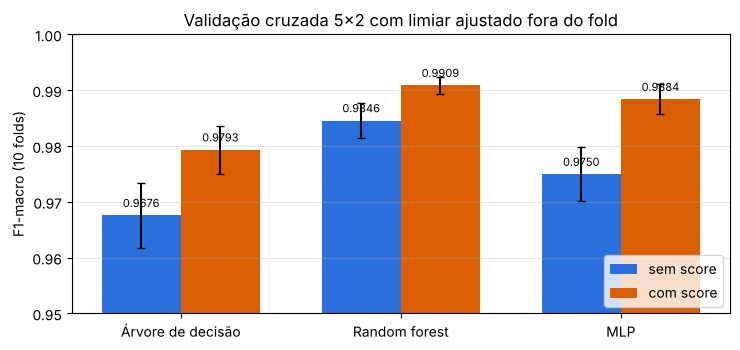

In [20]:
# [IA] Gráfico: F1-macro dos três modelos, sem e com score_ids_legado
fig, ax = plt.subplots(figsize=(7.5, 3.6))
nomes = [n for n, _, _ in FINAIS.values()]; x = np.arange(len(nomes)); w = 0.36
for i, (v, cor) in enumerate([("sem score", AZUL), ("com score", LARANJA)]):
    t = tabela_final[tabela_final.versao == v].set_index("modelo").loc[nomes]
    ax.bar(x + (i - 0.5) * w, t["f1_macro"], w, yerr=t["desvio"], color=cor, label=v, capsize=3)
    for xi, val in zip(x, t["f1_macro"]): ax.text(xi + (i - 0.5) * w, val + 0.0015, f"{val:.4f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(nomes); ax.set_ylim(0.95, 1.0); ax.set_ylabel("F1-macro (10 folds)")
ax.set_title("Validação cruzada 5×2 com limiar ajustado fora do fold"); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [21]:
# [IA] Matriz de confusão da random forest final (sem score), somando os 10 folds
mc = ex.metricas_por_classe(final["rf"])
pd.DataFrame([[mc["VN"], mc["FP"]], [mc["FN"], mc["VP"]]], index=["real normal", "real anomaly"], columns=["previsto normal", "previsto anomaly"])

,previsto normal,previsto anomaly
real normal,106440,74
real anomaly,141,3493


## 8. Escolha do melhor modelo

**Modelo escolhido: random forest** (300 árvores, `max_features` = 0,2, `max_depth` = 30), com `service`/`flag` imputados por uma random forest, mediana nos números, `log1p` nas contagens, `StandardScaler`, one-hot com os serviços raros juntos, sem balanceamento e com **limiar de decisão de 0,37**, que é a mediana dos limiares escolhidos fora de cada fold.

**Por que ela:**
1. Teve o maior F1-macro nas duas versões: **0,9846 ± 0,0031** sem o score e **0,9909 ± 0,0016** com ele.
2. Foi também o modelo mais estável entre os folds.
3. Na classe `anomaly`, que é a que mais pesa no F1-macro, acerta **96,1% dos ataques** (revocação) com **97,9% de precisão**. A cada 100 alarmes, só 2 são falsos.
4. É mais simples de explicar e reproduzir do que o ensemble, que não ganhou dela.

**Desempenho esperado no teste:** cerca de 0,985 de F1-macro sem o `score_ids_legado` e 0,991 com ele, **se o teste tiver a mesma distribuição do treino limpo**. Há dois motivos para cautela:
- o teste não pode passar pela remoção de linhas. Conferimos que ele já tem 0 linhas duplicadas e 0 linhas idênticas às do treino, e que o `score_ids_legado` se distribui nele de forma parecida com o treino limpo. Isso é um bom sinal;
- o pipeline prevê cerca de 4,9% de anomalias no teste, contra 3,3% no treino limpo. O teste pode ter mais ataques, e talvez ataques que não aparecem no treino.

**Para a Etapa 4:** treinar esse pipeline no treino limpo inteiro, aplicar no `teste_sem_rotulo.csv` com o limiar escolhido aqui, gerar a submissão e analisar a explicabilidade do modelo.